## Q2(e). A Transparent Risk-Neutral GARCH Scenario

The GARCH(1,1) parameters estimated in Question 1 describe conditional volatility under the physical probability measure. They cannot be directly interpreted as risk-neutral parameters without additional assumptions.

We construct a transparent working risk-neutral scenario by retaining the estimated GARCH persistence and shock-response coefficients, adjusting the long-run variance level to the selected call's implied volatility, and imposing the risk-neutral martingale condition on the stock-price process.

This is an illustrative pricing scenario rather than a uniquely calibrated risk-neutral GARCH model.

### Risk-Neutral GARCH Parameter Construction

We retain the ARCH and GARCH coefficients estimated under the physical measure as an explicit working assumption. The GARCH intercept is adjusted so that the long-run annualized volatility equals the selected call's implied volatility.

Since the historical GARCH model was estimated using percentage returns, the implied variance is converted into squared-percentage units before calculating the risk-neutral intercept.

This variance-level matching is not a full option-market calibration and does not uniquely identify the risk-neutral volatility process.

In [2]:
# Q2(e): Working risk-neutral GARCH parameters

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from time import perf_counter

s0 = 209.05
K = 210
r = 0.045


alpha_q = 0.04870716302121454
beta_q = 0.756853643016407
h0_p = 17.59736237837547     #Latest conditional variance (% squared) from Q1

sigma = 0.497988  # Replace with full-precision Q1 call IV

sigma_iv = sigma  # Common implied volatility from Q2

persistence_q = alpha_q + beta_q

# Convert annualized decimal volatility to daily percentage-squared variance
long_run_variance_q = (sigma_iv * 100)**2 / 252

omega_q = (1 - persistence_q) * long_run_variance_q

print("Risk-neutral persistence:", persistence_q)
print("Target daily variance (% squared):", long_run_variance_q)
print("Risk-neutral omega:", omega_q)
print("Target annualized volatility:", sigma_iv)



Risk-neutral persistence: 0.8055608060376216
Target daily variance (% squared): 9.840954291428572
Risk-neutral omega: 1.9134672202459804
Target annualized volatility: 0.497988


### Risk-Neutral GARCH Variance Simulation

We first simulate the conditional variance process under the working risk-neutral GARCH(1,1) specification.

The variance recursion is

\[
h_{t+1}=\omega_Q+\alpha_Q\epsilon_t^2+\beta_Qh_t,
\qquad
\epsilon_t=\sqrt{h_t}z_t,
\quad z_t\sim N(0,1).
\]

The variance is measured in squared percentage-return units, consistent with the historical GARCH estimation. We begin with a single 10-day simulation to verify the recursion before generating Monte Carlo stock-price paths.

In [3]:
rng = np.random.default_rng(42)

n_days = 10
z = rng.standard_normal(n_days)

h = np.zeros(n_days+1)
h[0] = h0_p

for t in range(n_days):
    eplison = np.sqrt(h[t]) * z[t]

    h[t+1] = (
        omega_q+
        alpha_q*eplison**2+
        beta_q*h[t]
    )

print("Normal shocks:", z)
print("Conditional variances:", h)
print("Shape:", h.shape)

Normal shocks: [ 0.30471708 -1.03998411  0.7504512   0.94056472 -1.95103519 -1.30217951
  0.1278404  -0.31624259 -0.01680116 -0.85304393]
Conditional variances: [17.59736238 15.31168055 14.30878864 13.13562689 12.42122024 13.61747782
 13.34459075 12.02399203 11.07244034 10.29383626 10.06924346]
Shape: (11,)


### Simulating a Stock Price Path under Risk-Neutral GARCH

We combine the previously simulated conditional variance path with the risk-neutral stock-price process.

The GARCH conditional variance is expressed in squared percentage-return units. Therefore, it must be divided by \(100^2\) when used in the log-price transition.

At each trading-day step, the stock-price transition uses the conditional variance known at the beginning of that step. The same standardized innovation is then used to update the next period's conditional variance.

The resulting stock-price path is one realization under the assumed working risk-neutral GARCH scenario.

In [4]:
stock = np.zeros(n_days + 1)
stock[0] = s0

dt = 1 / 252

for t in range(n_days):


    daily_variance = h[t] / 10000

    log_return = (
        r * dt
        - 0.5 * daily_variance
        + np.sqrt(daily_variance) * z[t]
    )

    stock[t+1] = stock[t]*np.exp(log_return)

print("Stock prices:", stock)
print("Shape:", stock.shape)

Stock prices: [209.05       211.59092297 203.03392088 208.76797796 215.90408502
 201.467881   191.91926942 192.72343761 190.54104996 190.36314604
 185.16148822]
Shape: (11,)


### Multi-Path Risk-Neutral GARCH Simulation

We extend the single-path GARCH simulation to 1,000 independent Monte Carlo paths over 63 trading-day steps.

Rows represent simulation dates, while columns represent independent paths. Each path starts from the same initial stock price and conditional variance but evolves according to its own normally distributed innovations.

The conditional variance is updated using the working risk-neutral GARCH(1,1) parameters. Stock-price returns use the conditional variance available at the beginning of each step.

In [5]:
rng = np.random.default_rng(42)

n_path = 1000
n_days = 63
dt = 1/252

z = rng.standard_normal((n_days,n_path))

stock = np.zeros((n_days+1, n_path))
h = np.zeros((n_days+1, n_path))

stock[0, :] = s0
h[0, :] = h0_p

for t in range(n_days):
    daily_variance = h[t, :]/10000

    log_return = (
        r * dt
        - 0.5 * daily_variance
        + np.sqrt(daily_variance) * z[t, :]
    )

    stock[t + 1, :] = stock[t, :] * np.exp(log_return)

    eplison = np.sqrt(h[t,:]) * z[t,:]

    h[t+1,:] = (
        omega_q+
        alpha_q*eplison**2+
        beta_q*h[t,:]
    )

print("Normal shocks:", z.shape)
print("Stock paths:", stock.shape)
print("Variance paths:", h.shape)
print("Terminal stock prices:", stock[-1, :].shape)

Normal shocks: (63, 1000)
Stock paths: (64, 1000)
Variance paths: (64, 1000)
Terminal stock prices: (1000,)


### Risk-Neutral Martingale Check

Under the working risk-neutral GARCH scenario, the expected terminal stock price should equal the initial stock price compounded at the risk-free rate.

We compare the Monte Carlo estimate of the terminal stock price with its theoretical risk-neutral expectation. The difference provides a numerical diagnostic of the simulated stock-price dynamics.

The current experiment uses 63 trading-day steps and 1,000 independent paths.

In [6]:
simulation_T = n_days/252

mc_mean = np.mean(stock[-1,:])
theoretical_mean = s0*np.exp(r*simulation_T)

print("Monte Carlo Mean:", mc_mean)
print("Theoretical Mean:", theoretical_mean)
print("Absolute Difference:", abs(mc_mean - theoretical_mean))
print("Relative Difference (%):",
      abs(mc_mean - theoretical_mean) / theoretical_mean * 100)


Monte Carlo Mean: 210.74824456076303
Theoretical Mean: 211.41509119369596
Absolute Difference: 0.6668466329329306
Relative Difference (%): 0.3154205450366709


### Monte Carlo Confidence Interval for the Martingale Check

We calculate a 95% confidence interval for the simulated mean terminal stock price using the sample standard deviation and standard error.

The theoretical risk-neutral expectation is compared with this interval to assess whether the observed difference is consistent with Monte Carlo sampling uncertainty.

In [7]:
terminal_stock = stock[-1,:]

M = len(terminal_stock)

sample_std = np.std(terminal_stock, ddof=1)
standard_error = sample_std/ np.sqrt(M)

ci_lower = mc_mean-1.96*standard_error
ci_upper = mc_mean+1.96*standard_error

print("Sample Standard Deviation:", sample_std)
print("Standard Error:", standard_error)
print("95% Confidence Interval:", (ci_lower, ci_upper))
print("Theoretical Mean:", theoretical_mean)

print(
    "Theoretical Mean Inside CI:",
    ci_lower <= theoretical_mean <= ci_upper
)

Sample Standard Deviation: 54.41804234881964
Standard Error: 1.7208495962976915
95% Confidence Interval: (np.float64(207.37537935201956), np.float64(214.1211097695065))
Theoretical Mean: 211.41509119369596
Theoretical Mean Inside CI: True


### GARCH Monte Carlo Call Option Pricing

Under the working risk-neutral GARCH scenario, the European call price is estimated as the discounted average terminal payoff.

For each simulated stock-price path, the terminal payoff is calculated as max(S_T − K, 0). The Monte Carlo estimator is the sample mean of these discounted payoffs.

We first verify the pricing calculation using 1,000 simulated paths before increasing the sample size for the final estimate.

In [8]:
d1 = (np.log(s0/K)+(r+0.5*sigma**2)*simulation_T)/(sigma*np.sqrt(simulation_T))
d2 = d1 - sigma*np.sqrt(simulation_T)

bs_call = s0*norm.cdf(d1)-K*np.exp(-r*simulation_T)*norm.cdf(d2)

terminal_stock = stock[-1,:]

call_payoff = np.maximum(terminal_stock -K, 0)
discounted_payoff = np.exp(-r*simulation_T)*call_payoff

garch_call_price = np.mean(discounted_payoff)

print("Payoff shape:", call_payoff.shape)
print("GARCH Call Price:", garch_call_price)
print("Black-Scholes Price:", bs_call)

Payoff shape: (1000,)
GARCH Call Price: 21.63041510023275
Black-Scholes Price: 21.35008471009705


### Confidence Interval for the GARCH Call Price

The Monte Carlo call price is estimated using the average discounted payoff across simulated paths.

We calculate the sample standard deviation of discounted payoffs and the corresponding standard error to construct an approximate 95% confidence interval.

We also inspect the terminal stock-price distribution to identify whether extreme simulated outcomes materially affect the estimated option price.

In [9]:
M = len(discounted_payoff)

payoff_std = np.std(discounted_payoff, ddof=1)
payoff_se = payoff_std / np.sqrt(M)

call_ci_lower = garch_call_price - 1.96 * payoff_se
call_ci_upper = garch_call_price + 1.96 * payoff_se

print("GARCH Call Price:", garch_call_price)
print("Payoff Standard Deviation:", payoff_std)
print("Call Standard Error:", payoff_se)
print("95% CI:", (call_ci_lower, call_ci_upper))

print("Maximum Terminal Stock Price:", np.max(terminal_stock))
print("Median Terminal Stock Price:", np.median(terminal_stock))
print("99th Percentile:", np.percentile(terminal_stock, 99))
print("Maximum Discounted Payoff:", np.max(discounted_payoff))

GARCH Call Price: 21.63041510023275
Payoff Standard Deviation: 35.48052776582415
Call Standard Error: 1.121992803248496
95% CI: (np.float64(19.4313092058657), np.float64(23.8295209945998))
Maximum Terminal Stock Price: 546.0963733417177
Median Terminal Stock Price: 206.33658749314174
99th Percentile: 358.28232537704133
Maximum Discounted Payoff: 332.33647820681756


In [10]:
# Convert daily variance in percentage-squared units
# into annualized volatility in decimal units.

annualized_vol = np.sqrt(h / 10000 * 252)

terminal_vol = annualized_vol[-1, :]

print("Median Terminal Volatility:", np.median(terminal_vol))
print("Mean Terminal Volatility:", np.mean(terminal_vol))
print("99th Percentile Volatility:", np.percentile(terminal_vol, 99))
print("Maximum Terminal Volatility:", np.max(terminal_vol))
print("Maximum Volatility Across All Paths:", np.max(annualized_vol))

print(
    "Correlation: Terminal Stock vs Terminal Volatility:",
    np.corrcoef(stock[-1, :], terminal_vol)[0, 1]
)

Median Terminal Volatility: 0.4922801623275893
Mean Terminal Volatility: 0.4982131822090696
99th Percentile Volatility: 0.583863402971347
Maximum Terminal Volatility: 0.6866680134452267
Maximum Volatility Across All Paths: 0.9614204072897458
Correlation: Terminal Stock vs Terminal Volatility: 0.07170730188928241


In [11]:
## Calculate Option price from Black Scholes 
valuation_date = pd.Timestamp("2026-10-09")
expiration_date = pd.Timestamp("2027-01-15")
calendar_days = (expiration_date - valuation_date).days
T = calendar_days /365
n_days = round(T * 252)

d1 = (np.log(s0/K)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)

bs_call = s0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2)

print(bs_call)

22.175019659856545


### GARCH Monte Carlo Convergence Function

This function simulates stock prices under the working risk-neutral GARCH(1,1) scenario. To reduce memory usage, only the current stock prices and conditional variances are retained rather than storing the full simulated paths.

In [12]:
def garch_mc(n_days, n_path, seed=42):
    start = perf_counter()

    rng = np.random.default_rng(seed)

    stock_t = np.full(n_path, s0)
    h_t  = np.full(n_path, h0_p)

    dt = 1/252

    ### Recursive GARCH Stock Price Simulation
    # At each trading step, independent standard normal shocks are generated for all simulation paths.
    # The stock prices are updated using risk-neutral log returns, while the conditional variances are updated using the GARCH(1,1) recursion. Only the current state of each path is retained.

    for t in range(n_days):
        z = rng.standard_normal(n_path)

        daily_variance = h_t/ 10000
        log_return = (
            r*dt
            -0.5*daily_variance
            +np.sqrt(daily_variance)*z
        )

        stock_t = stock_t*np.exp(log_return)
        epsilon = np.sqrt(h_t) * z

        h_t = (
            omega_q
            + alpha_q * epsilon**2
            + beta_q * h_t
        )

    simulation_T = n_days / 252

    call_payoff = np.maximum(stock_t - K, 0)
    discounted_payoff = np.exp(-r * simulation_T) * call_payoff

    price = np.mean(discounted_payoff)

    payoff_std = np.std(discounted_payoff, ddof=1)
    standard_error = payoff_std / np.sqrt(n_path)

    ci_lower = price - 1.96 * standard_error
    ci_upper = price + 1.96 * standard_error

    runtime = perf_counter() - start

    return {
        "N Paths": n_path,
        "Price": price,
        "Standard Error": standard_error,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "Runtime (s)": runtime
    }

### Initial Validation of the GARCH Monte Carlo Function

The function is tested using 1,000 simulated paths to verify that the estimated option price, confidence interval, and runtime are returned correctly.

In [13]:
test_result = garch_mc(n_days= n_days, n_path=10000, seed=42)

for key, value in test_result.items():
    print(f"{key}:{value}")

N Paths:10000
Price:22.39533264941495
Standard Error:0.3854211347818871
CI Lower:21.639907225242453
CI Upper:23.150758073587447
Runtime (s):0.016893799998797476


### Monte Carlo Convergence Analysis

The risk-neutral GARCH simulation is repeated using increasing numbers of paths to assess the convergence of the estimated call price.

For each simulation size, the estimated price, standard error, 95% confidence interval, and runtime are recorded. The standard error is expected to decrease approximately at the rate of 1/sqrt(N).

In [14]:
path_size = [1000, 5000, 10000, 50000, 100000, 200000]

results = []

for n in path_size:
    result = garch_mc(n_days=n_days, n_path=n, seed=42)
    results.append(result)

convergence_df = pd.DataFrame(results)
display(convergence_df)

,N Paths,Price,Standard Error,CI Lower,CI Upper,Runtime (s)
0,1000,22.503905,1.170898,20.208944,24.798866,0.003461
1,5000,23.101151,0.557137,22.009163,24.193139,0.008418
2,10000,22.395333,0.385421,21.639907,23.150758,0.014379
3,50000,23.111551,0.175098,22.768360,23.454742,0.081229
4,100000,23.033052,0.123089,22.791798,23.274306,0.121637
5,200000,22.750521,0.086301,22.581371,22.919672,0.481722


### GARCH Monte Carlo Convergence Visualization

The convergence of the risk-neutral GARCH option price is evaluated across increasing simulation sizes.

The first plot shows the estimated call price with 95% confidence intervals and the constant-volatility Black–Scholes benchmark.

The second plot compares the observed Monte Carlo standard error with the theoretical inverse-square-root convergence rate.

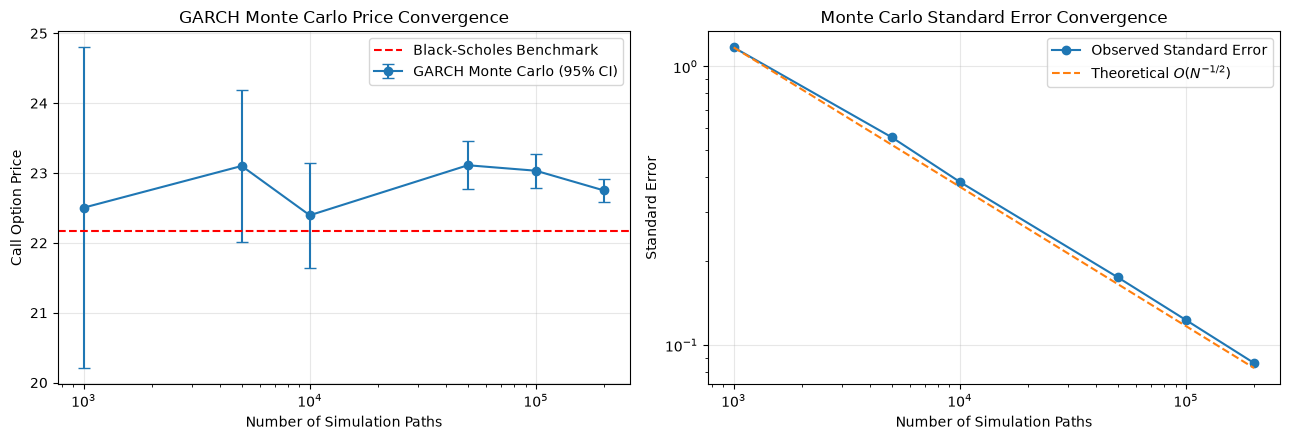

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

n = convergence_df["N Paths"].to_numpy()
price = convergence_df["Price"].to_numpy()
se = convergence_df["Standard Error"].to_numpy()

# Price convergence with confidence intervals
axes[0].errorbar(
    n, price,
    yerr=1.96 * se,
    fmt="o-",
    capsize=4,
    label="GARCH Monte Carlo (95% CI)"
)

axes[0].axhline(
    bs_call,
    color="red",
    linestyle="--",
    label="Black-Scholes Benchmark"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Number of Simulation Paths")
axes[0].set_ylabel("Call Option Price")
axes[0].set_title("GARCH Monte Carlo Price Convergence")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Standard error convergence
theoretical_se = se[0] * np.sqrt(n[0] / n)

axes[1].loglog(
    n, se, "o-",
    label="Observed Standard Error"
)

axes[1].loglog(
    n, theoretical_se, "--",
    label=r"Theoretical $O(N^{-1/2})$"
)

axes[1].set_xlabel("Number of Simulation Paths")
axes[1].set_ylabel("Standard Error")
axes[1].set_title("Monte Carlo Standard Error Convergence")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### GARCH Monte Carlo Convergence and Model Interpretation

The GARCH Monte Carlo experiment uses a trading-day simulation horizon approximating the option's calendar maturity. Increasing the number of simulation paths substantially reduces the width of the 95% confidence intervals, and the observed standard errors closely follow the theoretical inverse-square-root convergence rate.

The GARCH price estimates fluctuate across simulation sizes rather than decreasing or increasing monotonically. At the largest simulation size, the estimated GARCH price is above the constant-volatility Black–Scholes benchmark, with the benchmark lying outside the reported 95% confidence interval. This suggests that the difference is not explained by Monte Carlo sampling error alone under the specified scenario.

The working risk-neutral GARCH construction retains the historical estimates of alpha and beta, adjusts omega to match the long-run variance implied by the selected call option, and uses the most recent fitted conditional variance as its initial state. This is a variance-matching assumption, not a full calibration of the GARCH dynamics to market option prices.

Because volatility is stochastic and cannot generally be perfectly hedged using only the underlying stock and risk-free asset, the market may be incomplete. Consequently, the risk-neutral volatility dynamics are not uniquely determined by no-arbitrage conditions alone. Different admissible assumptions may generate different option values.

The GARCH estimate should therefore be interpreted as a scenario-based valuation rather than a uniquely calibrated market price.

### Exporting GARCH Monte Carlo Pricing Results

The GARCH Monte Carlo convergence results are exported for the final reconciliation. The simulation with the largest number of paths is used as the representative estimate, together with its confidence interval and measured runtime. The volatility specification is identified separately from the constant-volatility Black–Scholes assumption.

In [16]:
from pathlib import Path

output_path = Path("../Data/processed/garch_mc_results.csv")

convergence_df.to_csv(output_path, index=False)

print("Saved:", output_path)
display(convergence_df.tail(3))

Saved: ..\Data\processed\garch_mc_results.csv


,N Paths,Price,Standard Error,CI Lower,CI Upper,Runtime (s)
3,50000,23.111551,0.175098,22.768360,23.454742,0.081229
4,100000,23.033052,0.123089,22.791798,23.274306,0.121637
5,200000,22.750521,0.086301,22.581371,22.919672,0.481722
